# Jakość danych, analiza eksploracyjna (IV, korelacje, DR w decylach) i polityka cech

----
## 0. Importy

In [1]:
import sys, json; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as cfg
from src.data import load_data, load_splits
from src.features import (build_base_frame, select_columns, Winsorizer, RareGrouper, information_value, CAT_COLS)
plt.style.use('default')

----
## 1. Ramka bazowa

In [2]:
df = load_data()
splits = load_splits()
tr = splits['train']
y_tr = df.loc[tr, cfg.TARGET]
X = build_base_frame(df)
X_tr = X.loc[tr]
print('ramka bazowa:', X.shape)
print('w tym kategorii:', len(CAT_COLS))

ramka bazowa: (3000, 142)
w tym kategorii: 4


In [3]:
print(df.select_dtypes(exclude='float').nunique())

szczegolnaFormaPrawna_Symbol       1
formaWlasnosci_Symbol             16
pkdKod                           379
wsk_liczba_dni_istnienia        2159
schemat_wsk_bilans                 3
schemat_wsk_rzis                   3
default                            2
dtype: int64


----
## 2. Jakość danych

In [4]:
raw = df.loc[tr].drop(columns=cfg.TARGET)
num_raw = raw.select_dtypes('number')
dq = pd.DataFrame({
    'braki_%': (num_raw.isna().mean() * 100).round(1),
    'inf_%': (np.isinf(num_raw).mean() * 100).round(1),
    'ujemne_%': ((num_raw < 0).mean() * 100).round(1),
    'skośność': num_raw.replace([np.inf, -np.inf], np.nan).skew().round(1),
})
print('kolumn z brakami lub inf:', ((dq['braki_%'] > 0) | (dq['inf_%'] > 0)).sum())
print('kolumn ze skośnością |s| > 2:', (dq['skośność'].abs() > 2).sum(), 'z', len(dq))
print('firmy z aktywami <= 0:', (df.loc[tr, 'Aktywa'] <= 0).sum())
print('firmy z przychodami = 0:', (df.loc[tr, 'przychody'] == 0).sum())
dq.to_csv(cfg.TAB_DIR / '02_data_quality.csv')
dq[(dq['braki_%'] > 0) | (dq['inf_%'] > 0)].sort_values('braki_%', ascending=False)

kolumn z brakami lub inf: 10
kolumn ze skośnością |s| > 2: 210 z 220
firmy z aktywami <= 0: 38
firmy z przychodami = 0: 361


,braki_%,inf_%,ujemne_%,skośność
RP_przeplywy_operacyjne,99.0,0.0,0.1,3.2
wsk_akt_generowania_got_2,99.0,0.0,0.1,1.8
wsk_zysk_CF_operacyjny,99.0,0.0,0.3,3.1
wsk_pokrycie_wyd_fin_gotowkowe_2,99.0,0.0,0.1,4.0
wsk_pokrycie_zob_kr_gotowkowe_2,99.0,0.0,0.1,0.6
wsk_zadluzenia_gotowki_2,99.0,0.0,0.0,4.1
RP_amortyzacja,95.1,0.0,0.0,4.3
wsk_plynnosc_biez_1,3.8,30.8,0.5,36.2
wsk_kapital_do_aktywa,1.5,0.3,0.0,1.4
wsk_struktura_kap_wlasnego_s_2,1.5,3.0,0.6,-44.8


**Wnioski:**
- braki dotyczą głównie rachunku przepływów pieniężnych (95–99% braków) – tych kolumn nie da się sensownie uzupełnić,
- `wsk_plynnosc_biez_1` ma 31% wartości inf (dzielenie przez zerowe zobowiązania bieżące) – traktujemy je jak brak,
- prawie wszystkie wskaźniki są bardzo skośne (210 z 220) – potrzebna winsoryzacja,
- 38 firm ma aktywa ≤ 0, a 361 zerowe przychody, więc część wskaźników to dzielenie przez zero lub bardzo małe liczby.

----
## 3. Selekcja kolumn

In [5]:
num_cols, reasons = select_columns(X_tr)
print(f'cechy liczbowe: {X_tr.shape[1] - len(CAT_COLS)} -> {len(num_cols)}')
print(pd.Series(reasons).value_counts().to_string())
features = {'numeric': num_cols, 'categorical': CAT_COLS, 'dropped': reasons}
(cfg.TAB_DIR / '02_cechy.json').write_text(json.dumps(features, ensure_ascii=False, indent=1))
pd.Series(reasons, name='powód').to_frame()

cechy liczbowe: 138 -> 125
duplikat innej kolumny    8
braki > 50%               5


,powód
wsk_akt_generowania_got_2,braki > 50%
wsk_pokrycie_wyd_fin_gotowkowe_2,braki > 50%
wsk_pokrycie_zob_kr_gotowkowe_2,braki > 50%
wsk_zadluzenia_gotowki_2,braki > 50%
wsk_zysk_CF_operacyjny,braki > 50%
wsk_rent_sprzedazy,duplikat innej kolumny
wsk_zysk_operacyjny_zob_1,duplikat innej kolumny
wsk_zadluzenie_gotowka,duplikat innej kolumny
wsk_ebitda_zobowiazan_odsetki_1,duplikat innej kolumny
wsk_ebitda_zobowiazan_odsetki_2,duplikat innej kolumny


Odpada 13 kolumn liczbowych: 5 z brakami > 50% (przepływy pieniężne) i 8 będących kopią innej kolumny (ten sam wskaźnik pod inną nazwą).

----
## 4. Capping

In [6]:
wins = Winsorizer(0.01, 0.99).fit(X_tr[num_cols])
Xw_tr = wins.transform(X_tr[num_cols])
effect = pd.DataFrame({'skośność_przed': X_tr[num_cols].skew(), 'skośność_po': Xw_tr.skew(),
                       'max_przed': X_tr[num_cols].max(), 'max_po': Xw_tr.max()})
print('mediana |skośności|: przed', round(effect.skośność_przed.abs().median(), 1),
      '-> po', round(effect.skośność_po.abs().median(), 1))
effect.loc[['wsk_ROA', 'wsk_plynnosc_biez_2', 'wsk_ogolnego_zadluzenia_1', 'log_aktywa']].round(2)

mediana |skośności|: przed 36.2 -> po 5.0


,skośność_przed,skośność_po,max_przed,max_po
wsk_ROA,22.63,-1.31,1116.97,0.71
wsk_plynnosc_biez_2,38.65,4.67,1041380.00,21118.81
wsk_ogolnego_zadluzenia_1,37.15,0.35,879.09,0.99
log_aktywa,-1.37,-1.41,20.80,18.20


Obcięcie do percentyli 1–99% zmniejsza medianę. Wartości skrajne, np. ROA = 1117, wynikają z dzielenia przez bliskie zera mianowniki – po obcięciu przestają dominować w modelu.

----
## 5. Zmienne kategoryczne

In [7]:
rare = RareGrouper(0.02).fit(X_tr[CAT_COLS])
C_tr = rare.transform(X_tr[CAT_COLS])
for c in ['pkd_sekcja', 'formaWlasnosci_Symbol']:
    t = pd.crosstab(C_tr[c], y_tr).rename(columns={0: 'dobre', 1: 'złe'})
    t['n'] = t.sum(axis=1); t['DR'] = (t['złe'] / t['n']).round(3)
    print(c); print(t.sort_values('n', ascending=False).to_string(), '\n')

pkd_sekcja
default     dobre  złe    n     DR
pkd_sekcja                        
G             351   58  409  0.142
M             300   55  355  0.155
C             219   28  247  0.113
F             201   24  225  0.107
L             140   24  164  0.146
J             135   17  152  0.112
inne           91   13  104  0.125
H              86   11   97  0.113
N              77   16   93  0.172
K              56    6   62  0.097
I              37   16   53  0.302
Q              43    6   49  0.122
A              42    5   47  0.106
D              33    9   42  0.214 

formaWlasnosci_Symbol
default                dobre  złe     n     DR
formaWlasnosci_Symbol                         
214                     1230  177  1407  0.126
215                      179   31   210  0.148
216                      148   34   182  0.187
0                        110   18   128  0.141
inne                     108   18   126  0.143
226                       36   10    46  0.217 



Rzadkie poziomy łączymy w „inne”. Najwyższe DR mają sekcje I (zakwaterowanie i gastronomia, 30%) i D (energetyka, 21%) oraz formy własności 216 i 226 (19–22%) – kategorie niosą informację, ale część poziomów jest mała, więc ich DR jest niepewne.

----
## 6. Siła predykcyjna (IV)

In [8]:
iv = {c: information_value(Xw_tr[c], y_tr) for c in num_cols}
iv.update({c: information_value(C_tr[c], y_tr) for c in CAT_COLS})
iv = pd.Series(iv, name='IV').sort_values(ascending=False)
siła = pd.cut(iv, [-1, 0.02, 0.1, 0.3, 0.5, 99], labels=['bezużyteczna', 'słaba', 'średnia', 'silna', 'podejrzana'])
iv_tab = pd.DataFrame({'IV': iv.round(3), 'siła': siła})
iv_tab.to_csv(cfg.TAB_DIR / '02_iv.csv')
print(iv_tab['siła'].value_counts().to_string())
iv_tab.head(20)

siła
średnia         72
słaba           36
silna           19
bezużyteczna     2
podejrzana       0


,IV,siła
wsk_struktury_kapitalu,0.422,silna
wsk_struktura_kap_wlasnego_2,0.421,silna
wsk_udzial_kap_wlasnego_aktywa_1,0.421,silna
wsk_struktura_kap_wlasnego_s_1,0.417,silna
wsk_kapital_do_aktywa,0.416,silna
wsk_mnoznik_kap_wl,0.398,silna
wsk_struktura_kap_obcego_s,0.395,silna
wsk_ogolnego_zadluzenia_2,0.391,silna
wsk_ogolnego_zadluzenia_1,0.386,silna
wsk_ROE,0.384,silna


 19 cech ma IV silne (0,3–0,5), żadna nie jest podejrzana (IV > 0,5, sygnał przecieku). Najsilniejsze cechy opisują strukturę kapitału i zadłużenie – i są to w praktyce różne wersje tego samego wskaźnika (podobne IV ≈ 0,42).

----
## 7. DR w decylach cech

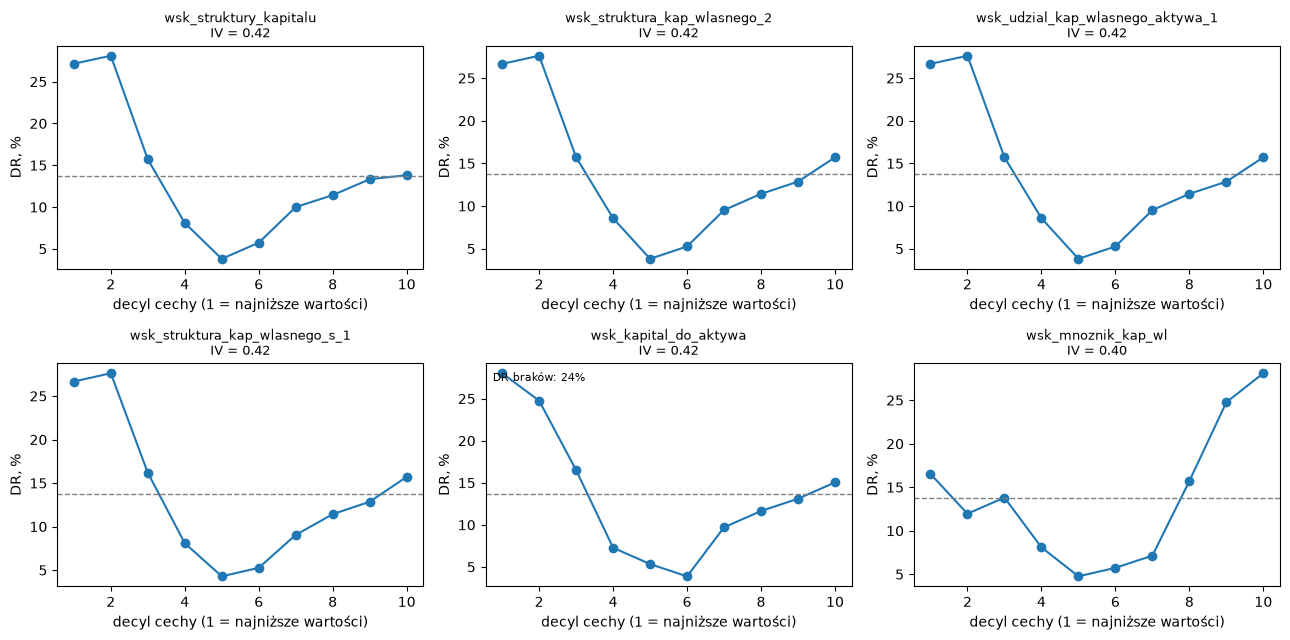

In [9]:
top = [c for c in iv.index if c in num_cols][:6]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axes.ravel(), top):
    bins = pd.qcut(Xw_tr[c], 10, duplicates='drop')
    dr = y_tr.groupby(bins, observed=True).mean()
    ax.plot(range(1, len(dr) + 1), dr.values * 100, marker='o')
    ax.axhline(y_tr.mean() * 100, ls='--', c='grey', lw=1)
    ax.set_title(f'{c}\nIV = {iv[c]:.2f}', fontsize=9)
    ax.set_xlabel('decyl cechy (1 = najniższe wartości)'); ax.set_ylabel('DR, %')
    if Xw_tr[c].isna().any():
        ax.text(0.02, 0.92, f'DR braków: {y_tr[Xw_tr[c].isna()].mean():.0%}', transform=ax.transAxes, fontsize=8)
plt.tight_layout(); plt.savefig(cfg.FIG_DIR / '02_dr_decyle.png', dpi=150); plt.show()

**Wnioski:** wykres pokazuje kształt zależności DR od cechy. Dla wskaźników struktury kapitału zależność nie jest monotoniczna (kształt U – ryzyko rośnie zarówno przy bardzo niskim, jak i bardzo wysokim kapitale własnym), dlatego te cechy dostają w binningu WoE wyjątek `U_SHAPE`.

----
## 8. Korelacje

pary |ρ| > 0,9: 164 | pary |ρ| > 0,7: 711 z 15625


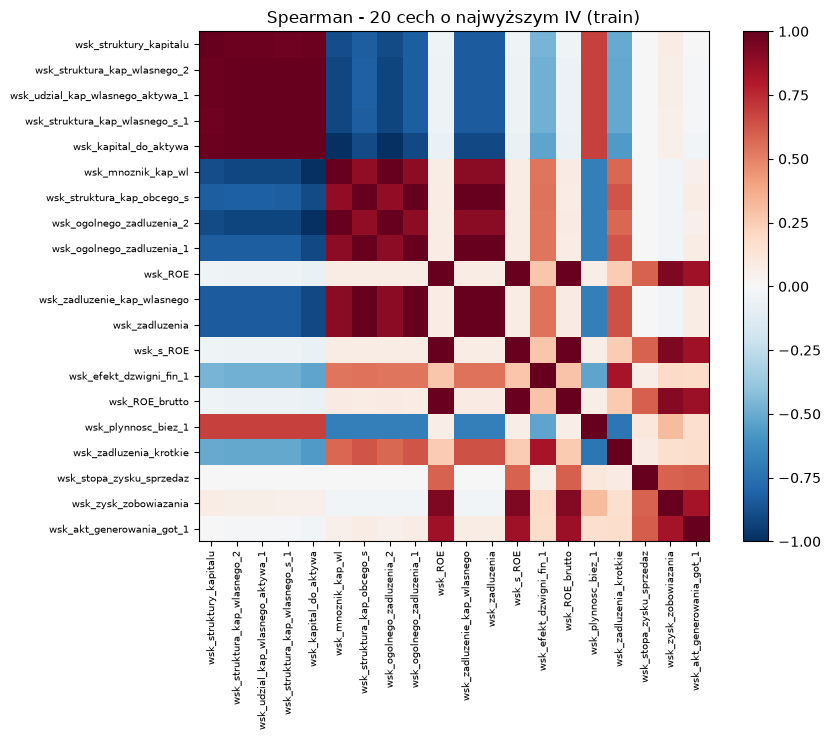

wsk_kapital_do_aktywa             wsk_udzial_kap_wlasnego_aktywa_1           1.000
wsk_rotacja_zobowiazan            wsk_udzial_zob_biez_sprzedaz_1             1.000
wsk_pokrycie_aktywow_kap_stalym   wsk_zast_kapitalu_wlasnego                 1.000
wsk_zadluzenie_kap_wlasnego       wsk_zadluzenia                             1.000
wsk_udzial_kap_wlasnego_aktywa_1  wsk_struktura_kap_wlasnego_2               1.000
wsk_kapital_do_aktywa             wsk_ogolnego_zadluzenia_2                 -1.000
                                  wsk_struktura_kap_wlasnego_2               1.000
                                  wsk_mnoznik_kap_wl                        -1.000
wsk_mnoznik_kap_wl                wsk_ogolnego_zadluzenia_2                  1.000
wsk_zob_oprocentowanych           wsk_zob_oprocentowanych_aktywa_rzeczowe    0.999
dtype: float64

In [10]:
corr = Xw_tr[num_cols].corr(method='spearman')
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print('pary |ρ| > 0,9:', (upper.abs() > 0.9).sum(), '| pary |ρ| > 0,7:', (upper.abs() > 0.7).sum(), 'z', len(upper))
top20 = [c for c in iv.index if c in num_cols][:20]
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr.loc[top20, top20], cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(20)); ax.set_xticklabels(top20, rotation=90, fontsize=7)
ax.set_yticks(range(20)); ax.set_yticklabels(top20, fontsize=7)
plt.colorbar(im, fraction=0.046); ax.set_title('Spearman - 20 cech o najwyższym IV (train)')
plt.tight_layout(); plt.savefig(cfg.FIG_DIR / '02_korelacje_top20.png', dpi=150); plt.show()
upper[upper.abs() > 0.9].sort_values(key=abs, ascending=False).head(10).round(3)

164 pary cech mają |ρ| > 0,9, a część par ρ = +-1 (ten sam wskaźnik liczony inaczej lub odwrotność). Cechy o najwyższym IV są ze sobą silnie skorelowane, więc do modelu logit wybieramy po jednej cesze z grupy.